# 🦟 Forecasting Dengue in Sri Lanka, District by District

**Goal:** forecast weekly dengue cases in each of Sri Lanka's 26 health districts **1–4 weeks ahead**,
and flag districts where cases are likely to rise above their usual level, early enough for
health teams to act (clean-up campaigns, fogging, preparing hospital beds).

**Why it matters:** dengue is Sri Lanka's biggest mosquito-borne disease. In 2017 the country had a
record epidemic of about 175,000 reported cases (3× a normal year).

### Contents
1. Data
2. Exploratory analysis: trends, seasons, districts, rainfall
3. Data quality: reporting delays and holiday effects
4. Framing the forecasting problem (and avoiding data leakage)
5. Backtest: model vs simple baselines
6. Prediction intervals
7. Early-warning alerts (the endemic channel)
8. What the model relies on
9. Latest forecast
10. Conclusions and limitations

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import dengue as D            # all project logic lives here (shared with train.py and the app)
from train import alert_scores

IMG = Path('images'); IMG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 13, 'axes.labelsize': 11})
BLUE, GREY, ORANGE, RED = '#2563EB', '#9CA3AF', '#E67E22', '#C0392B'

## 1. Data

- **Cases:** weekly reported dengue cases per district from the Weekly Epidemiological Reports of
  the Epidemiology Unit (Ministry of Health), collected in the `denguedatahub` package by
  Dr. Thiyanga S. Talagala. Downloaded with `fetch_dengue.py`.
- **Weather:** daily rainfall, temperature and humidity per district from NASA POWER
  (`fetch_weather.py`), aggregated to the same weeks.

In [2]:
panel = D.load_cases()
weeks = pd.DatetimeIndex(panel.week_start.unique()).sort_values()
weather = D.load_weather(weeks=weeks)
HAS_WEATHER = weather is not None

print(f"{len(panel):,} district-weeks | {panel.district.nunique()} districts | "
      f"{weeks.min():%d %b %Y} -> {weeks.max():%d %b %Y} ({len(weeks)} weeks)")
print("Weather data:", "yes" if HAS_WEATHER else "not downloaded yet (run fetch_weather.py)")
panel.head()

26,312 district-weeks | 26 districts | 23 Dec 2006 -> 09 May 2026 (1012 weeks)
Weather data: yes


,week_start,district,cases
0,2006-12-23,Ampara,0.0
1,2006-12-30,Ampara,0.0
2,2007-01-06,Ampara,0.0
3,2007-01-13,Ampara,0.0
4,2007-01-20,Ampara,0.0


In [3]:
raw = pd.read_csv('data/dengue_weekly.csv')
print("Missing district-weeks in the raw file:", len(panel) - len(raw), "(filled by interpolation)")
print("Negative or missing case counts:", int((raw.cases < 0).sum() + raw.cases.isna().sum()))

Missing district-weeks in the raw file: 1 (filled by interpolation)
Negative or missing case counts: 0


## 2. Exploratory Analysis
### 2.1 National trend

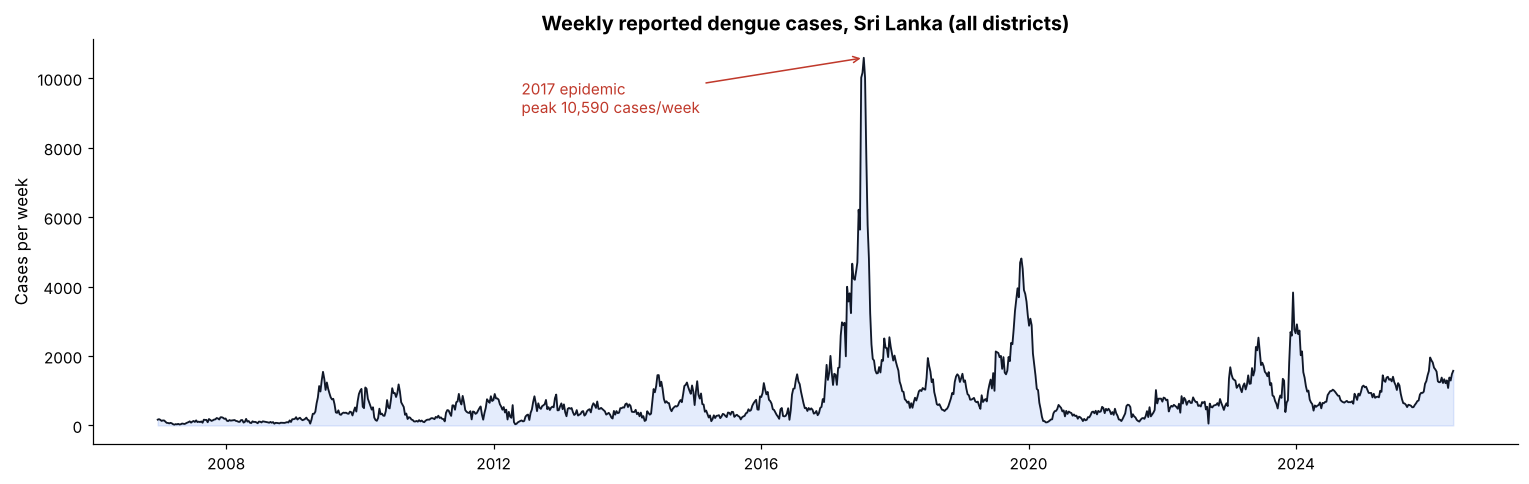

week_start
2007      6038
2008      5515
2009     26552
2010     25006
2011     22381
2012     23342
2013     22472
2014     35650
2015     22180
2016     35666
2017    175389
2018     50667
2019     96590
2020     29404
2021     19862
2022     33025
2023     74983
2024     50217
2025     50799


In [4]:
national = panel.groupby('week_start').cases.sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(national.index, national.values, color='#111827', lw=1.2)
ax.fill_between(national.index, national.values, color=BLUE, alpha=0.12)
peak = national.idxmax()
ax.annotate(f"2017 epidemic\npeak {national.max():,.0f} cases/week", xy=(peak, national.max()),
            xytext=(pd.Timestamp('2012-06-01'), national.max() * 0.85),
            arrowprops=dict(arrowstyle='->', color=RED), color=RED, fontsize=10)
ax.set_title('Weekly reported dengue cases, Sri Lanka (all districts)', fontweight='bold')
ax.set_ylabel('Cases per week')
plt.tight_layout(); plt.savefig(IMG / 'national_trend.png', dpi=150, bbox_inches='tight'); plt.show()

yearly = panel[panel.week_start.dt.year.between(2007, 2025)].groupby(panel.week_start.dt.year).cases.sum()
print(yearly.astype(int).to_string())

### 2.2 Seasonality: two peaks a year
Sri Lanka has two monsoons: the **south-west monsoon (May–September)** and the **north-east monsoon
(December–February)**. Dengue follows them.

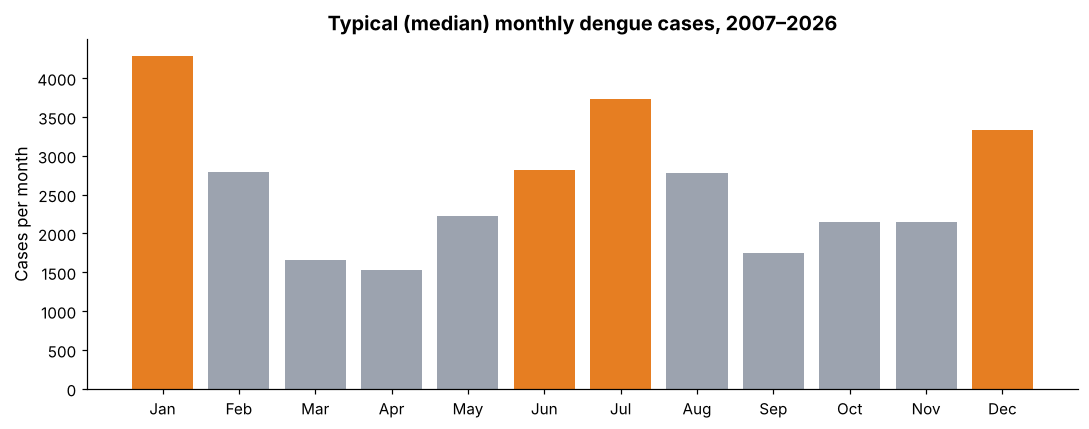

In [5]:
month = panel.assign(month=panel.week_start.dt.month, year=panel.week_start.dt.year)
monthly = month.groupby(['year', 'month']).cases.sum().groupby('month').median()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, color=[ORANGE if m in (6, 7, 12, 1) else GREY for m in monthly.index])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Typical (median) monthly dengue cases, 2007–2026', fontweight='bold')
ax.set_ylabel('Cases per month')
plt.tight_layout(); plt.savefig(IMG / 'seasonality.png', dpi=150, bbox_inches='tight'); plt.show()

### 2.3 Districts: where are the cases?

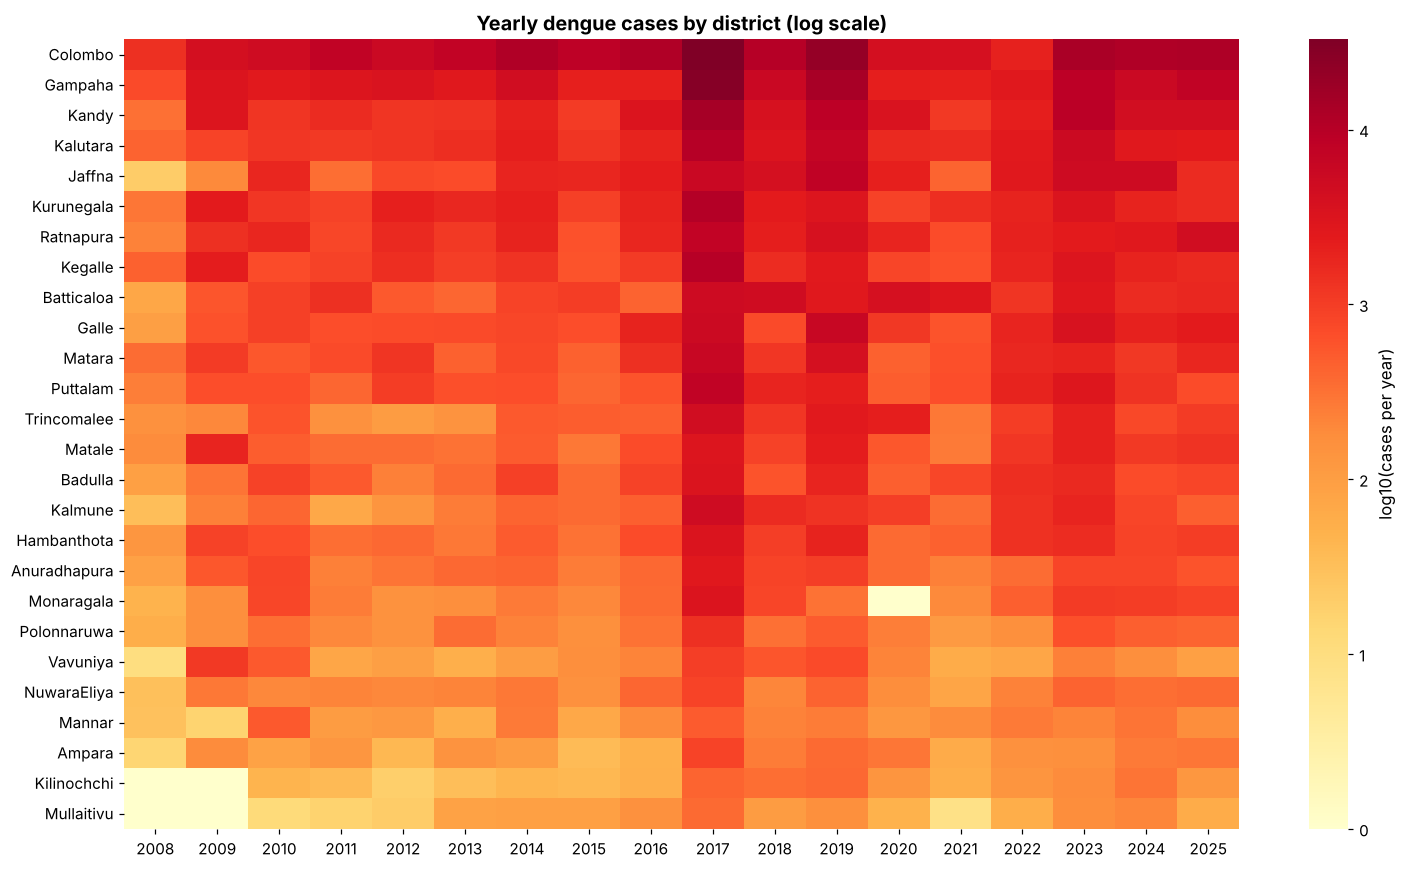

Share of all cases: Colombo 21.7 % | Gampaha 12.8 % | top 5 together 54.4 %


In [6]:
pivot = (panel.assign(year=panel.week_start.dt.year)
              .query('2008 <= year <= 2025')
              .pivot_table(index='district', columns='year', values='cases', aggfunc='sum'))
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(np.log10(pivot + 1), cmap='YlOrRd', ax=ax, cbar_kws={'label': 'log10(cases per year)'})
ax.set_title('Yearly dengue cases by district (log scale)', fontweight='bold'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(IMG / 'district_heatmap.png', dpi=150, bbox_inches='tight'); plt.show()

share = (pivot.sum(axis=1) / pivot.values.sum() * 100).round(1)
print("Share of all cases: Colombo", share['Colombo'], "% | Gampaha", share['Gampaha'], "% | top 5 together",
      share.head(5).sum().round(1), "%")

Colombo and Gampaha (the densely populated Western Province) carry about a third of all cases,
while northern districts like Mullaitivu and Kilinochchi have very few. One model has to work for
both, which is why it is trained on **log cases** (a jump from 2 to 4 and from 200 to 400 look the same).

### 2.4 Does rainfall lead dengue?

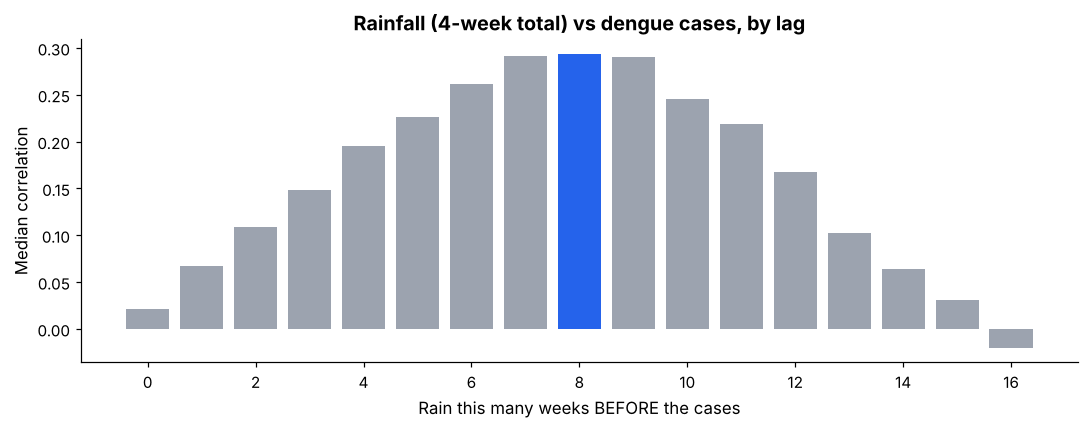

Strongest link: rain about 8 weeks before the cases (median r = 0.29)


In [7]:
if HAS_WEATHER:
    w = panel.merge(weather, on=['district', 'week_start'])
    corr = []
    for district, g in w.groupby('district'):
        g = g.sort_values('week_start')
        logc = np.log1p(g.cases)
        # remove the seasonal pattern first so we are not just correlating two seasonal curves
        logc = logc - logc.rolling(52, center=True, min_periods=26).mean()
        rain = g.rain_mm.rolling(4).sum()
        rain = rain - rain.rolling(52, center=True, min_periods=26).mean()
        for lag in range(0, 17):
            corr.append({'district': district, 'lag': lag, 'r': logc.corr(rain.shift(lag))})
    corr = pd.DataFrame(corr)
    med = corr.groupby('lag').r.median()

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(med.index, med.values, color=[BLUE if v == med.max() else GREY for v in med.values])
    ax.set_xticks(range(0, 17, 2))
    ax.set_xlabel('Rain this many weeks BEFORE the cases'); ax.set_ylabel('Median correlation')
    ax.set_title('Rainfall (4-week total) vs dengue cases, by lag', fontweight='bold')
    plt.tight_layout(); plt.savefig(IMG / 'rain_lag.png', dpi=150, bbox_inches='tight'); plt.show()
    print(f"Strongest link: rain about {med.idxmax()} weeks before the cases (median r = {med.max():.2f})")
else:
    print("Weather not downloaded yet: run `python fetch_weather.py`, then re-run this notebook.")

Rain creates breeding sites, eggs take about 1–2 weeks to become adult mosquitoes, and the virus
needs another 1–2 weeks inside the mosquito and about a week in a person before symptoms appear.
So rain should lead cases by several weeks. That is why the model uses rainfall **0–3, 4–7 and 8–11
weeks before** the forecast date, which is also information available at forecast time.

## 3. Data Quality: Reporting Delays and Holidays

Some weeks show a sudden drop, often followed by a spike the next week. That pattern is
**reporting delay**: cases from one week get reported in the next. Several districts dip together
around **mid-April (Sinhala and Tamil New Year)**, when offices close.

180 sudden one-week drops (below 25% of the surrounding weeks)
Most common months: {4: 30, 6: 20, 1: 19}


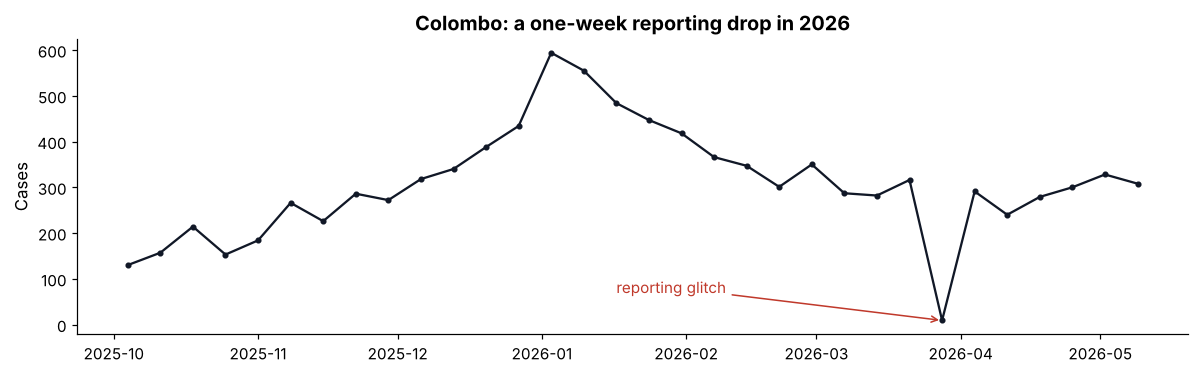

In [8]:
wide = panel.pivot(index='week_start', columns='district', values='cases')
neighbours = pd.concat([wide.shift(k) for k in (-2, -1, 1, 2)]).groupby(level=0).median()
drops = ((wide < 0.25 * neighbours) & (neighbours >= 20)).stack()
drops = drops[drops].reset_index()[['week_start', 'district']]
print(f"{len(drops)} sudden one-week drops (below 25% of the surrounding weeks)")
print("Most common months:", drops.week_start.dt.month.value_counts().head(3).to_dict())

col = wide['Colombo']['2025-10-01':'2026-05-31']
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(col.index, col.values, marker='o', ms=3, color='#111827')
low = col.idxmin(); ax.annotate('reporting glitch', xy=(low, col.min()), xytext=(low - pd.Timedelta(weeks=10), col.min() + 60),
                                arrowprops=dict(arrowstyle='->', color=RED), color=RED)
ax.set_title('Colombo: a one-week reporting drop in 2026', fontweight='bold'); ax.set_ylabel('Cases')
plt.tight_layout(); plt.show()

**Should we clean these?** I tested replacing sudden drops with the median of the previous 4 weeks
(a rule that only uses past data, so it would also work in real time). The model got **slightly
worse** one week ahead (MAE 12.08 vs 11.73, tested before adding weather), because the dip itself is informative: it predicts the
catch-up spike next week. So the raw reported numbers are kept, and evaluation is always done on
what was actually reported.

## 4. Framing the Forecasting Problem

We stand at week **t** (the latest reported week) and forecast week **t + h** for h = 1, 2, 3, 4.

| Decision | Choice | Why |
|---|---|---|
| Strategy | One model per horizon ("direct") | No error compounding from feeding forecasts back in |
| Scope | One **global** model for all districts | Small districts borrow patterns from big ones; 26× more training data |
| Target | Change in log(cases + 1) from week t | Tree models can't predict above values seen in training; predicting the *change* lets them follow record epidemics |
| Algorithm | LightGBM gradient boosting | Strong on tabular data, handles the district category and non-linear effects |
| Features | Last 8 weeks, rolling means (4–26 wks), trend, same season last year, national trend, week of year, plus lagged rain / temperature / humidity when weather data is available | Only data available at week t, so **no leakage** (a unit test checks this) |
| Uncertainty | Two extra quantile models (10% and 90%) | Gives an 80% range, not just one number |

**Baselines a model must beat:**
- **Naive:** next weeks = this week (surprisingly hard to beat for weekly epidemics)
- **Average of the last 4 weeks**
- **Seasonal naive:** same week last year

In [9]:
base = D.base_features(panel, weather)
example = D.horizon_features(base, 4)
features = D.feature_columns(example)
print(f"{len(features)} features for the 4-weeks-ahead model:")
print(", ".join(features))

29 features for the 4-weeks-ahead model:
district, y_lag0, y_lag1, y_lag2, y_lag3, y_lag4, y_lag5, y_lag6, y_lag7, y_mean4, y_mean8, y_mean13, y_mean26, y_std8, y_trend4, y_hist_mean, nat_lag0, nat_trend4, rain_0_3, rain_4_7, rain_8_11, temp_0_3, temp_4_7, hum_0_3, hum_4_7, woy_sin, woy_cos, y_last_year, y_last_year_mean3


## 5. Backtest: Model vs Baselines

**Expanding-window backtest.** For each test year (2022, 2023, 2024, 2025): train only on rows
whose target week is *before* that year, then forecast every week of it. This copies real use
exactly, unlike a random train/test split, which would leak the future into training.

The metric is **MAE**: the average absolute error in cases per district per week.

In [10]:
TEST_YEARS = (2022, 2023, 2024, 2025)
res = D.backtest(base, TEST_YEARS, use_weather=HAS_WEATHER)
mae = D.score(res)
mae['improvement_vs_naive_%'] = ((1 - mae.point / mae.naive) * 100).round(1)
mae.round(2)

,point,naive,mean4,seasonal_naive,improvement_vs_naive_%
horizon,,,,,
1,11.73,12.37,13.31,29.2,5.1
2,13.15,14.18,15.41,29.2,7.2
3,14.53,16.58,17.32,29.2,12.3
4,15.75,18.35,19.09,29.2,14.2


In [11]:
if HAS_WEATHER:
    res_nw = D.backtest(base, TEST_YEARS, use_weather=False)
    compare = pd.DataFrame({'with weather': D.score(res, cols=('point',))['point'],
                            'without weather': D.score(res_nw, cols=('point',))['point']})
    compare['weather gain %'] = ((1 - compare['with weather'] / compare['without weather']) * 100).round(1)
    display(compare.round(2))
else:
    print("Weather comparison skipped: weather data not downloaded yet.")

,with weather,without weather,weather gain %
horizon,,,
1,11.73,11.73,-0.0
2,13.15,13.23,0.6
3,14.53,15.07,3.6
4,15.75,16.33,3.5


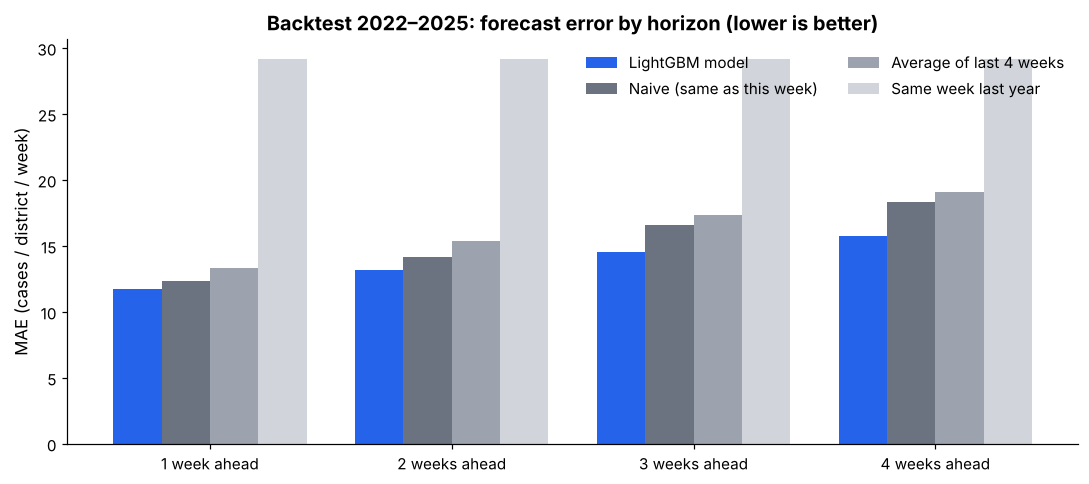

In [12]:
names = {'point': 'LightGBM model', 'naive': 'Naive (same as this week)', 'mean4': 'Average of last 4 weeks',
         'seasonal_naive': 'Same week last year'}
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(4); width = 0.2
for i, (col, colour) in enumerate(zip(names, [BLUE, '#6B7280', GREY, '#D1D5DB'])):
    ax.bar(x + (i - 1.5) * width, mae[col], width, label=names[col], color=colour)
ax.set_xticks(x); ax.set_xticklabels([f'{h} week{"s" if h > 1 else ""} ahead' for h in D.HORIZONS])
ax.set_ylabel('MAE (cases / district / week)'); ax.legend(frameon=False, ncol=2)
ax.set_title('Backtest 2022–2025: forecast error by horizon (lower is better)', fontweight='bold')
plt.tight_layout(); plt.savefig(IMG / 'backtest_mae.png', dpi=150, bbox_inches='tight'); plt.show()

### 5.1 Error by year: the 2023 surge is the hardest

In [13]:
D.score(res, by='test_year').round(2)

,point,naive,mean4,seasonal_naive
test_year,,,,
2022,12.47,13.53,12.73,20.24
2023,22.51,23.51,26.21,38.68
2024,10.10,13.61,14.72,36.34
2025,10.12,10.86,11.53,21.70


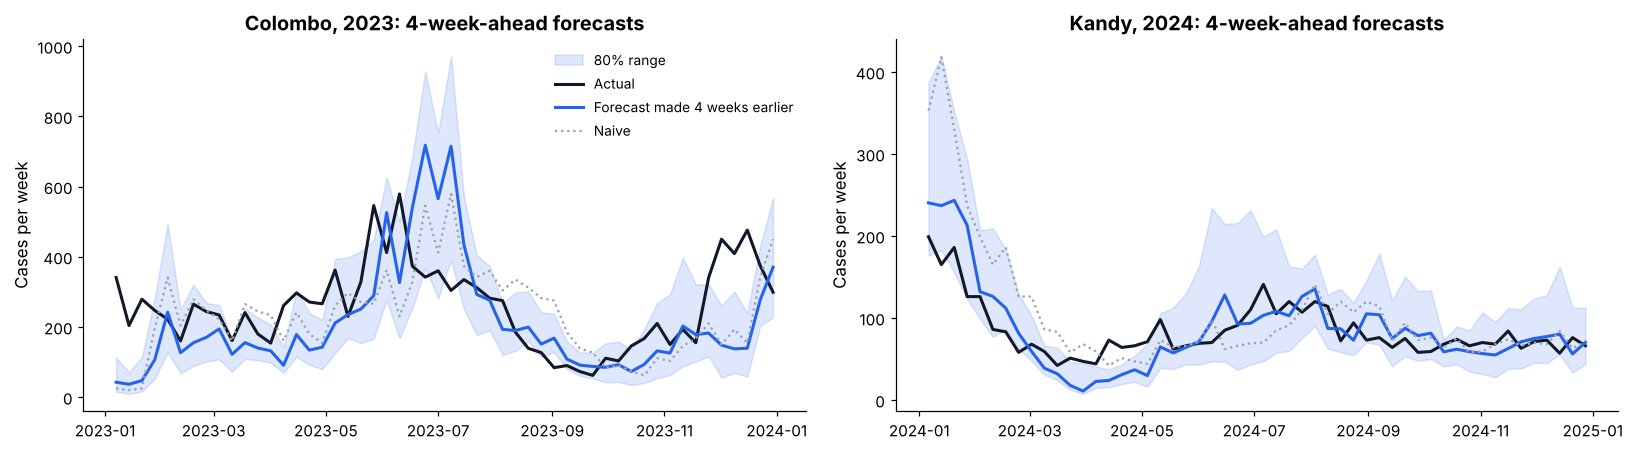

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=False)
for ax, (district, year) in zip(axes, [('Colombo', 2023), ('Kandy', 2024)]):
    b = res[(res.district == district) & (res.test_year == year) & (res.horizon == 4)].sort_values('target_week')
    ax.fill_between(b.target_week, b.low, b.high, color=BLUE, alpha=0.15, label='80% range')
    ax.plot(b.target_week, b.target_cases, color='#111827', lw=2, label='Actual')
    ax.plot(b.target_week, b.point, color=BLUE, lw=2, label='Forecast made 4 weeks earlier')
    ax.plot(b.target_week, b.naive, color=GREY, ls=':', label='Naive')
    ax.set_title(f'{district}, {year}: 4-week-ahead forecasts', fontweight='bold'); ax.set_ylabel('Cases per week')
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(IMG / 'forecast_vs_actual.png', dpi=150, bbox_inches='tight'); plt.show()

The model beats the naive forecast in every test year. 2023, the year of a sudden nationwide surge,
is the hardest (MAE 22.5 vs 23.5 for naive; without weather features the model only tied naive that
year). Like every forecaster it lags behind sudden turning points: four weeks ahead, it cannot know
about a surge that has not started yet.

## 6. Prediction Intervals

In [15]:
coverage = res.groupby('horizon').apply(D.interval_coverage)
print("Share of actual values inside the 80% range, by horizon:")
print(coverage.round(3).to_string())
print(f"Overall: {D.interval_coverage(res):.1%} (target 80%)")

Share of actual values inside the 80% range, by horizon:
horizon
1    0.763
2    0.749
3    0.741
4    0.725
Overall: 74.4% (target 80%)


The ranges are slightly too narrow (about 75% instead of 80%), mainly because surprise surges are
outside anything the model has learned. This could be fixed with conformal calibration (future work).

## 7. Early-Warning Alerts: the Endemic Channel

Public-health teams don't only care about the number of cases; they care whether it's **unusual
for this district at this time of year**. The classic tool is the *endemic channel*:

- **Usual level:** median of the same 5-week window in each of the previous 5 years
- **Usual upper line:** 75th percentile of those 25 weeks
- A week is an **alert week** if cases are above the upper line

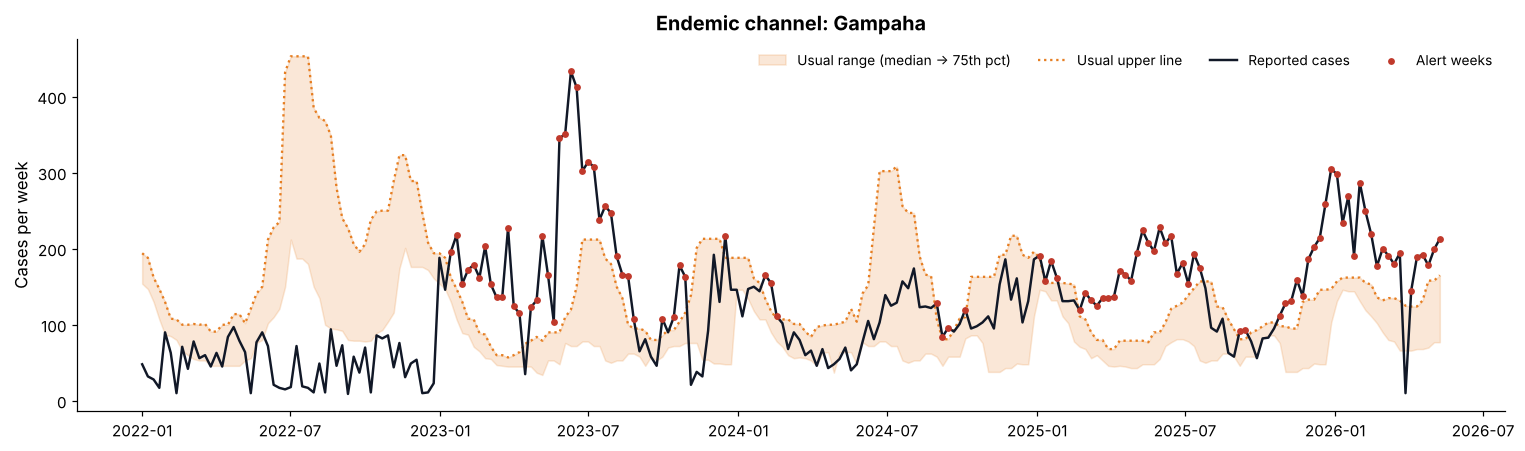

In [16]:
channel = D.channel_table(panel)
h_ = panel.merge(channel, on=['district', 'week_start'])
g = h_[(h_.district == 'Gampaha') & (h_.week_start >= '2022-01-01')]

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.fill_between(g.week_start, g.typical, g.upper, color=ORANGE, alpha=0.18, label='Usual range (median → 75th pct)')
ax.plot(g.week_start, g.upper, color=ORANGE, ls=':', lw=1.5, label='Usual upper line')
ax.plot(g.week_start, g.cases, color='#111827', lw=1.6, label='Reported cases')
above = g[g.cases > g.upper]
ax.scatter(above.week_start, above.cases, color=RED, s=12, zorder=3, label='Alert weeks')
ax.set_title('Endemic channel: Gampaha', fontweight='bold'); ax.set_ylabel('Cases per week'); ax.legend(frameon=False, ncol=4, fontsize=9)
plt.tight_layout(); plt.savefig(IMG / 'endemic_channel.png', dpi=150, bbox_inches='tight'); plt.show()

### 7.1 Choosing the alert threshold (on validation years, not test years)
Using the central forecast is cautious: when it alerts it's usually right, but it misses many
rises. Missing an outbreak is worse than a false alarm, so the alert compares a value between the
central forecast (a = 0) and the top of the 80% range (a = 1) with the upper line.
`a` is chosen on **2019–2021**, so the test years 2022–2025 stay untouched.

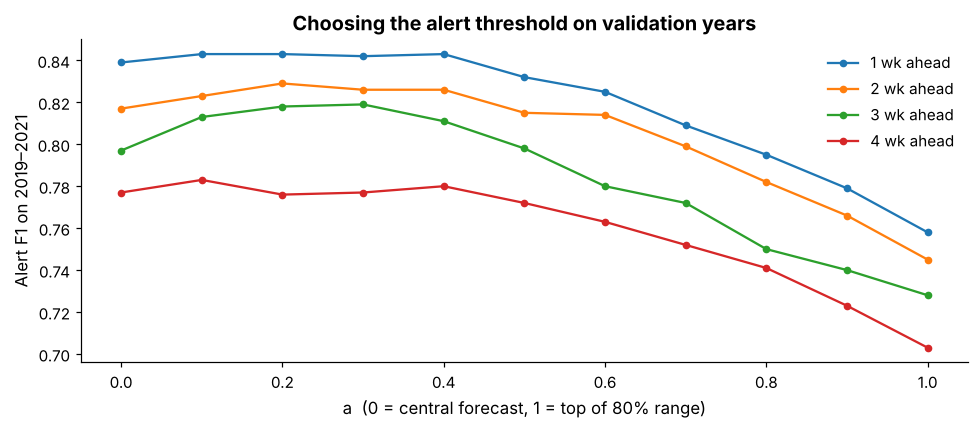

Chosen a per horizon: {1: 0.1, 2: 0.2, 3: 0.3, 4: 0.1}


In [17]:
val = D.backtest(base, (2019, 2020, 2021), use_weather=HAS_WEATHER)
grid = np.round(np.arange(0, 1.01, 0.1), 1)
f1 = pd.DataFrame({h: [alert_scores(val[val.horizon == h].assign(av=D.alert_value(val.point, val.high, a)), channel, 'av')['f1']
                       for a in grid] for h in D.HORIZONS}, index=grid)
best_a = f1.idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for h in D.HORIZONS:
    ax.plot(grid, f1[h], marker='o', ms=4, label=f'{h} wk ahead')
ax.set_xlabel('a  (0 = central forecast, 1 = top of 80% range)'); ax.set_ylabel('Alert F1 on 2019–2021')
ax.set_title('Choosing the alert threshold on validation years', fontweight='bold'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("Chosen a per horizon:", best_a.to_dict())

In [18]:
rows = []
for h in D.HORIZONS:
    r = res[res.horizon == h].assign(av=lambda d: D.alert_value(d.point, d.high, best_a[h]))
    for name, col in [('Model (tuned threshold)', 'av'), ('Model (central forecast)', 'point'), ('Naive', 'naive')]:
        rows.append({'horizon': h, 'method': name, **alert_scores(r, channel, col)})
alerts = pd.DataFrame(rows)
alerts.pivot(index='method', columns='horizon', values='f1').round(3)

horizon,1,2,3,4
method,,,,
Model (central forecast),0.696,0.664,0.637,0.604
Model (tuned threshold),0.703,0.688,0.668,0.622
Naive,0.695,0.667,0.637,0.625


In [19]:
alerts[alerts.method != 'Model (central forecast)'].pivot(index='method', columns='horizon', values='recall').round(3)

horizon,1,2,3,4
method,,,,
Model (tuned threshold),0.689,0.708,0.730,0.591
Naive,0.697,0.672,0.646,0.637


On the untouched test years the tuned alerts beat the naive approach on F1 **1–3 weeks ahead**,
with higher recall at 2–3 weeks. **Four weeks ahead they are only on par with naive** (F1 0.62 vs
0.63): the F1 curve on the validation years is flat, so the chosen threshold is not very stable.
I report this as it is rather than re-tuning on the test years, which would be cheating.

## 8. What the Model Relies On

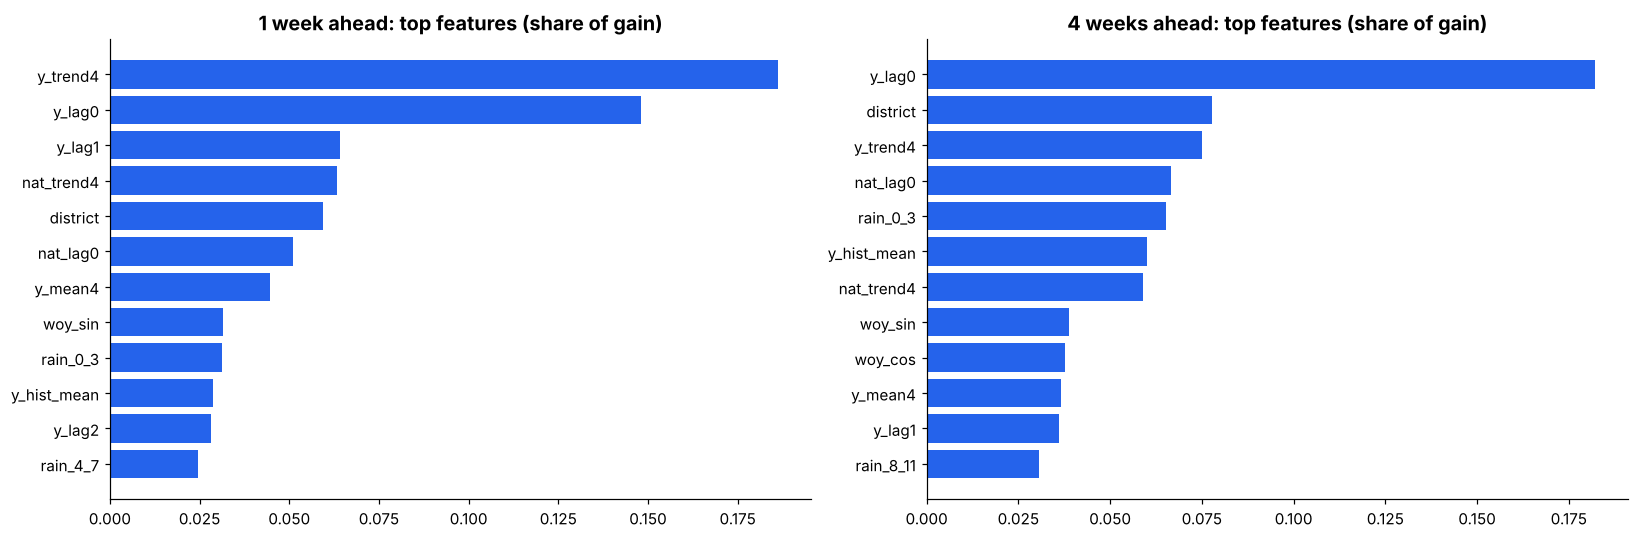

In [20]:
import joblib
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, h in zip(axes, (1, 4)):
    m = joblib.load(f'models/model_h{h}.pkl')
    imp = pd.Series(m['models']['point'].booster_.feature_importance('gain'), index=m['features'])
    imp = (imp / imp.sum()).nlargest(12).iloc[::-1]
    ax.barh(imp.index, imp.values, color=BLUE)
    ax.set_title(f'{h} week{"s" if h > 1 else ""} ahead: top features (share of gain)', fontweight='bold')
plt.tight_layout(); plt.savefig(IMG / 'feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()

One week ahead, the model leans on the most recent weeks. Four weeks ahead, longer averages, the
time of year and last year's level matter more, because recent weeks say less about a month away.

## 9. Latest Forecast

In [21]:
fc = pd.read_csv('outputs/forecast_latest.csv', parse_dates=['origin_week', 'target_week'])
h4 = fc[fc.horizon == 4].sort_values('point', ascending=False)
print(f"Forecast made from the week starting {fc.origin_week.max():%d %b %Y}, "
      f"for the week starting {h4.target_week.iloc[0]:%d %b %Y}")
print("Alerts:", h4.alert.value_counts().to_dict())
h4[['district', 'cases_latest', 'point', 'low', 'high', 'typical', 'upper', 'alert']].head(10).round(0)

Forecast made from the week starting 09 May 2026, for the week starting 06 Jun 2026
Alerts: {'Normal': 16, 'Elevated': 9, 'High': 1}


,district,cases_latest,point,low,high,typical,upper,alert
82,Colombo,308.0,255.0,136.0,324.0,200.0,302.0,Normal
84,Gampaha,213.0,200.0,93.0,274.0,90.0,217.0,Normal
101,Ratnapura,168.0,152.0,69.0,230.0,64.0,94.0,High
89,Kandy,135.0,136.0,66.0,190.0,70.0,161.0,Normal
88,Kalutara,157.0,128.0,62.0,188.0,62.0,92.0,Elevated
95,Matara,93.0,79.0,41.0,130.0,40.0,58.0,Elevated
83,Galle,104.0,78.0,40.0,118.0,26.0,69.0,Elevated
90,Kegalle,73.0,65.0,34.0,92.0,44.0,68.0,Normal
92,Kurunegala,45.0,48.0,23.0,68.0,60.0,77.0,Normal
85,Hambanthota,58.0,43.0,24.0,77.0,20.0,41.0,Elevated


## 10. Conclusions

- A single LightGBM model per horizon, trained on all 26 districts, **beats every simple baseline**
  at 1–4 weeks ahead in an honest expanding-window backtest (2022–2025). The gain over "same as
  this week" grows with the horizon, from about 5% one week ahead to about 14% four weeks ahead.
- **Rainfall helps most for longer horizons:** weather features cut the 3–4-week error by about 3.6%
  and have no effect one week ahead, which matches the biology (rain → mosquitoes → cases takes weeks).
- **Alerts** based on the endemic channel beat the naive approach 1–3 weeks ahead; 4 weeks ahead
  they are on par with it.
- Weekly dengue is hard to forecast; the naive forecast is a strong baseline. Being honest about the
  size of the gain matters more than a perfect-looking score.

### Limitations
- **Reported** cases depend on testing, reporting delays and holidays, not only on infections.
- The model cannot foresee surges that have not started yet (new serotypes, as in 2017).
- 80% ranges cover about 75% of outcomes: slightly over-confident.
- Kalmunai is a health division reported separately from Ampara, not an administrative district.

### Future work
- Conformal prediction for calibrated intervals
- Population data to forecast **incidence per 100,000** (fairer comparison between districts)
- Hierarchical reconciliation so district forecasts add up to the national forecast
- Daily or weekly automatic data refresh and a deployed alert e-mail